In [22]:
codePath = "./SourceCode/ReplicationPackage/"
dataPath = './SourceCode/ReplicationPackage/data/COPY/'
ground_truth = './SourceCode/ReplicationPackage/data/ground-truth.xlsx'

import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
py = sys.executable  # run the scripts with this notebook's Python environment

def show(folder):
    """Display the figures and result tables that a script saved in `folder`."""
    for f in sorted(Path(folder).iterdir()):
        if f.suffix == ".png": display(Image(str(f), width=900))
        elif f.name == "metrics.csv": display(pd.read_csv(f))
        elif f.name == "statistics_summary.txt": print(f.read_text())

A main contribution of this study is an emotion-labeled mobile app review dataset, created while actively studying agreement between annotators. The dataset was built in batches (iterations): each iteration used a unique set of app reviews and a different set of annotators. Each LLM, however, received the entire set of reviews and produced a single output file, so the first script, `code/data_processing/split_annotations.py`, splits that file into smaller files based on the iteration each review came from. This makes it easier to consolidate the agreement between the different annotators in each iteration.

In [23]:
split_input = f"{dataPath}/annotations/llm/temperature-00/gpt-4o-0-annotations.xlsx"  # Edit: LLM output file to split
!{py} {codePath}code/data_processing/split_annotations.py --input_file {split_input} --output_dir {dataPath}/annotations/iterations/

Created ./SourceCode/ReplicationPackage/data/COPY//annotations/iterations/iteration_3\iteration_3_gpt-4o-0.xlsx


Consolidates the annotations of a set of annotators. For each iteration, the script loads the set's annotations of that iteration's reviews and, for each review, selects an emotion label only if at least 2 annotators in the set selected it. The consolidated iterations are then merged into a single file. Consolidation lets us treat a group of annotators as one additional annotator, for example Ann_A (all human annotators), GPT_A, Mistral_A and Gemini_A (all runs of that LLM), and LLM_A (all runs of all LLMs).

In [24]:
llm_runs = {  # Edit: LLM name -> its annotator runs (as named in the iteration files)
    "gpt-4o": "gpt-4o-1 gpt-4o-2 gpt-4o-3",
    "mistral-large-2411": "mistral-large-2411-1 mistral-large-2411-2 mistral-large-2411-3",
    "gemini-2-0-flash": "gemini-2-0-flash-1 gemini-2-0-flash-2 gemini-2-0-flash-3",
}
agreements = {n: f"{dataPath}/agreements/agreement_{'-'.join(sorted(r.split()))}.xlsx" for n, r in llm_runs.items()}  # per-LLM output files

for runs in [*llm_runs.values(), " ".join(llm_runs.values())]:  # each LLM, then all LLMs combined (LLM_A)
    !{py} {codePath}code/evaluation/agreement.py --input-folder {dataPath}/annotations/iterations/ --output-folder {dataPath}/agreements/ --annotators {runs}

Starting agreement processing for folder: ./SourceCode/ReplicationPackage/data/COPY//annotations/iterations/

Processing subfolder: iteration_0
Skipping iteration folder: iteration_0

Processing subfolder: iteration_1
Skipping iteration folder: iteration_1

Processing subfolder: iteration_10
['iteration', '10', 'agreement']
['iteration', '10', 'agreement', 'Ann', '1-Ann', '2-Ann', '3-Ann', '4-Ann', '5']
['iteration', '10', 'agreement', 'gemini-2-0-flash-1-gemini-2-0-flash-2-gemini-2-0-flash-3']
['iteration', '10', 'agreement', 'gpt-4o-1-gpt-4o-2-gpt-4o-3']
['iteration', '10', 'agreement', 'LLM']
['iteration', '10', 'agreement', 'mistral-large-2411-1-mistral-large-2411-2-mistral-large-2411-3']
['iteration', '10', 'Ann', '2']
['iteration', '10', 'Ann', '3']
['iteration', '10', 'Ann', '4']
['iteration', '10', 'discussion']
['iteration', '10', 'gemini-2-0-flash-1']
['iteration', '10', 'gemini-2-0-flash-2']
['iteration', '10', 'gemini-2-0-flash-3']
['iteration', '10', 'gemini-2-0-flash']
['

Now we record the emotion statistics of each LLM's consolidated annotations (GPT_A, Mistral_A, Gemini_A): the frequency of each emotion label and the correlation between emotions.

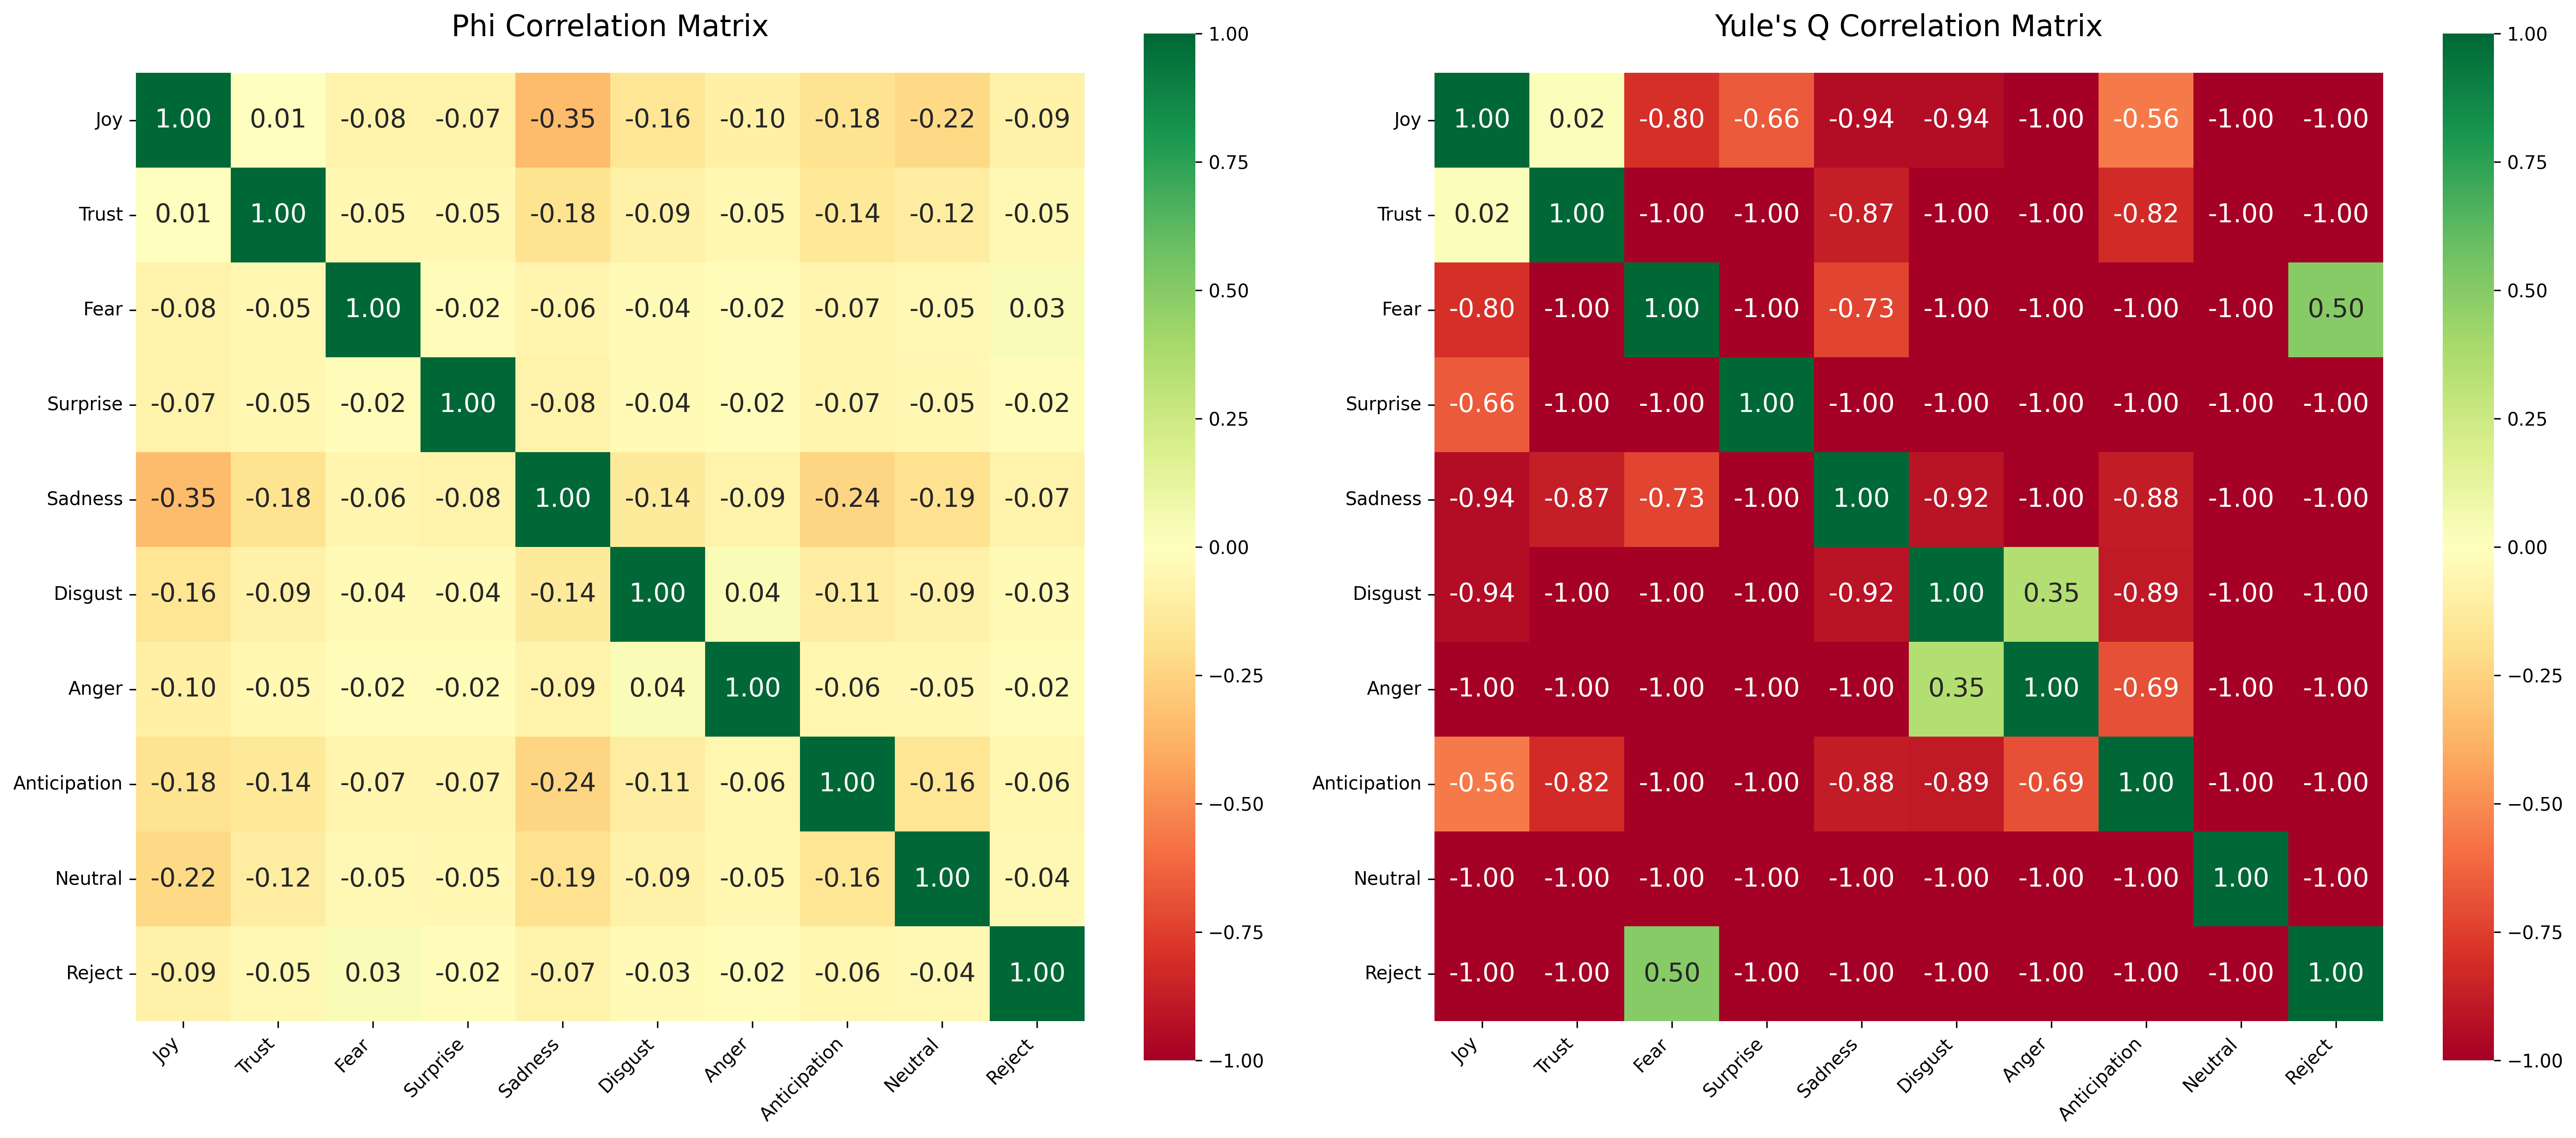

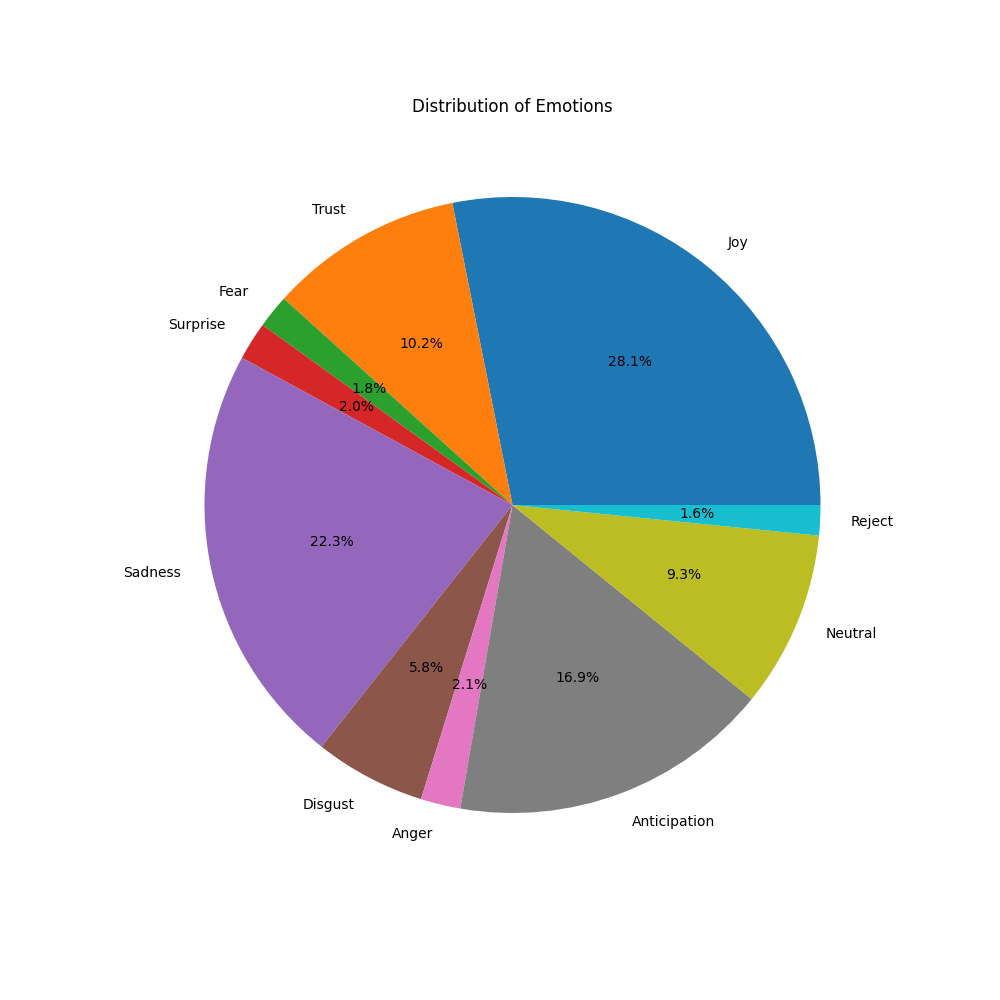

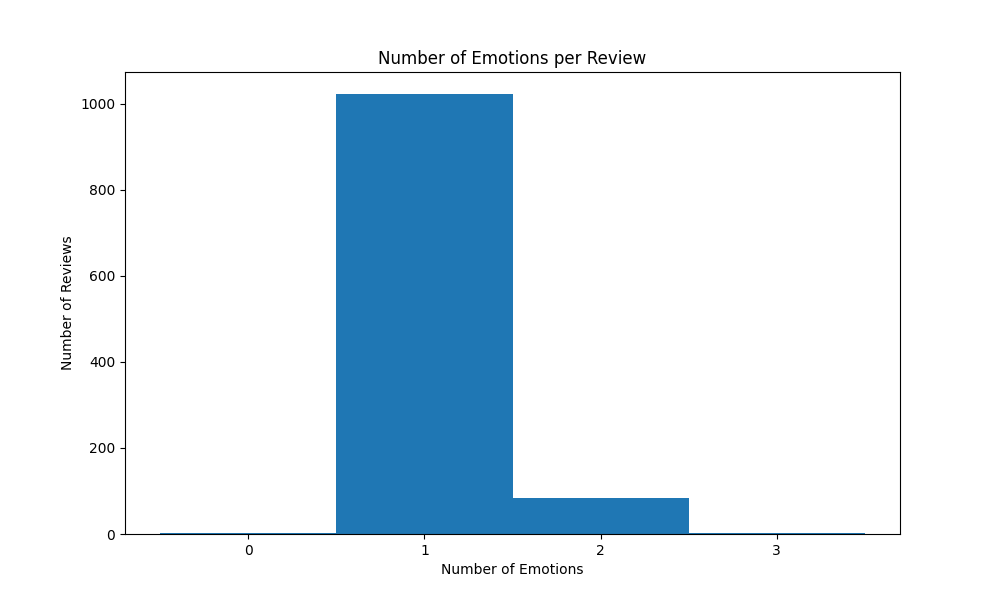

Emotion Distribution:
              Count  Percentage
Joy             337       28.13
Sadness         267       22.29
Anticipation    202       16.86
Trust           122       10.18
Neutral         111        9.27
Disgust          70        5.84
Anger            25        2.09
Surprise         24        2.00
Fear             21        1.75
Reject           19        1.59

Emotions per Review Statistics:
count    1112.000000
mean        1.077338
std         0.286744
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         3.000000

Histogram Data (Emotions per Review):
Number of Emotions | Count of Reviews
-----------------------------------
        0         |        3       
        1         |      1023      
        2         |       83       
        3         |        3       


Reviews with Zero Emotions:
------------------------
5eed8c92-b117-4aa3-8f4a-ff72d961eb32
425b71c1-6701-475c-a8df-56095b960581
ee80411c-0ee3-4b94-82bb-9833e163ad1e




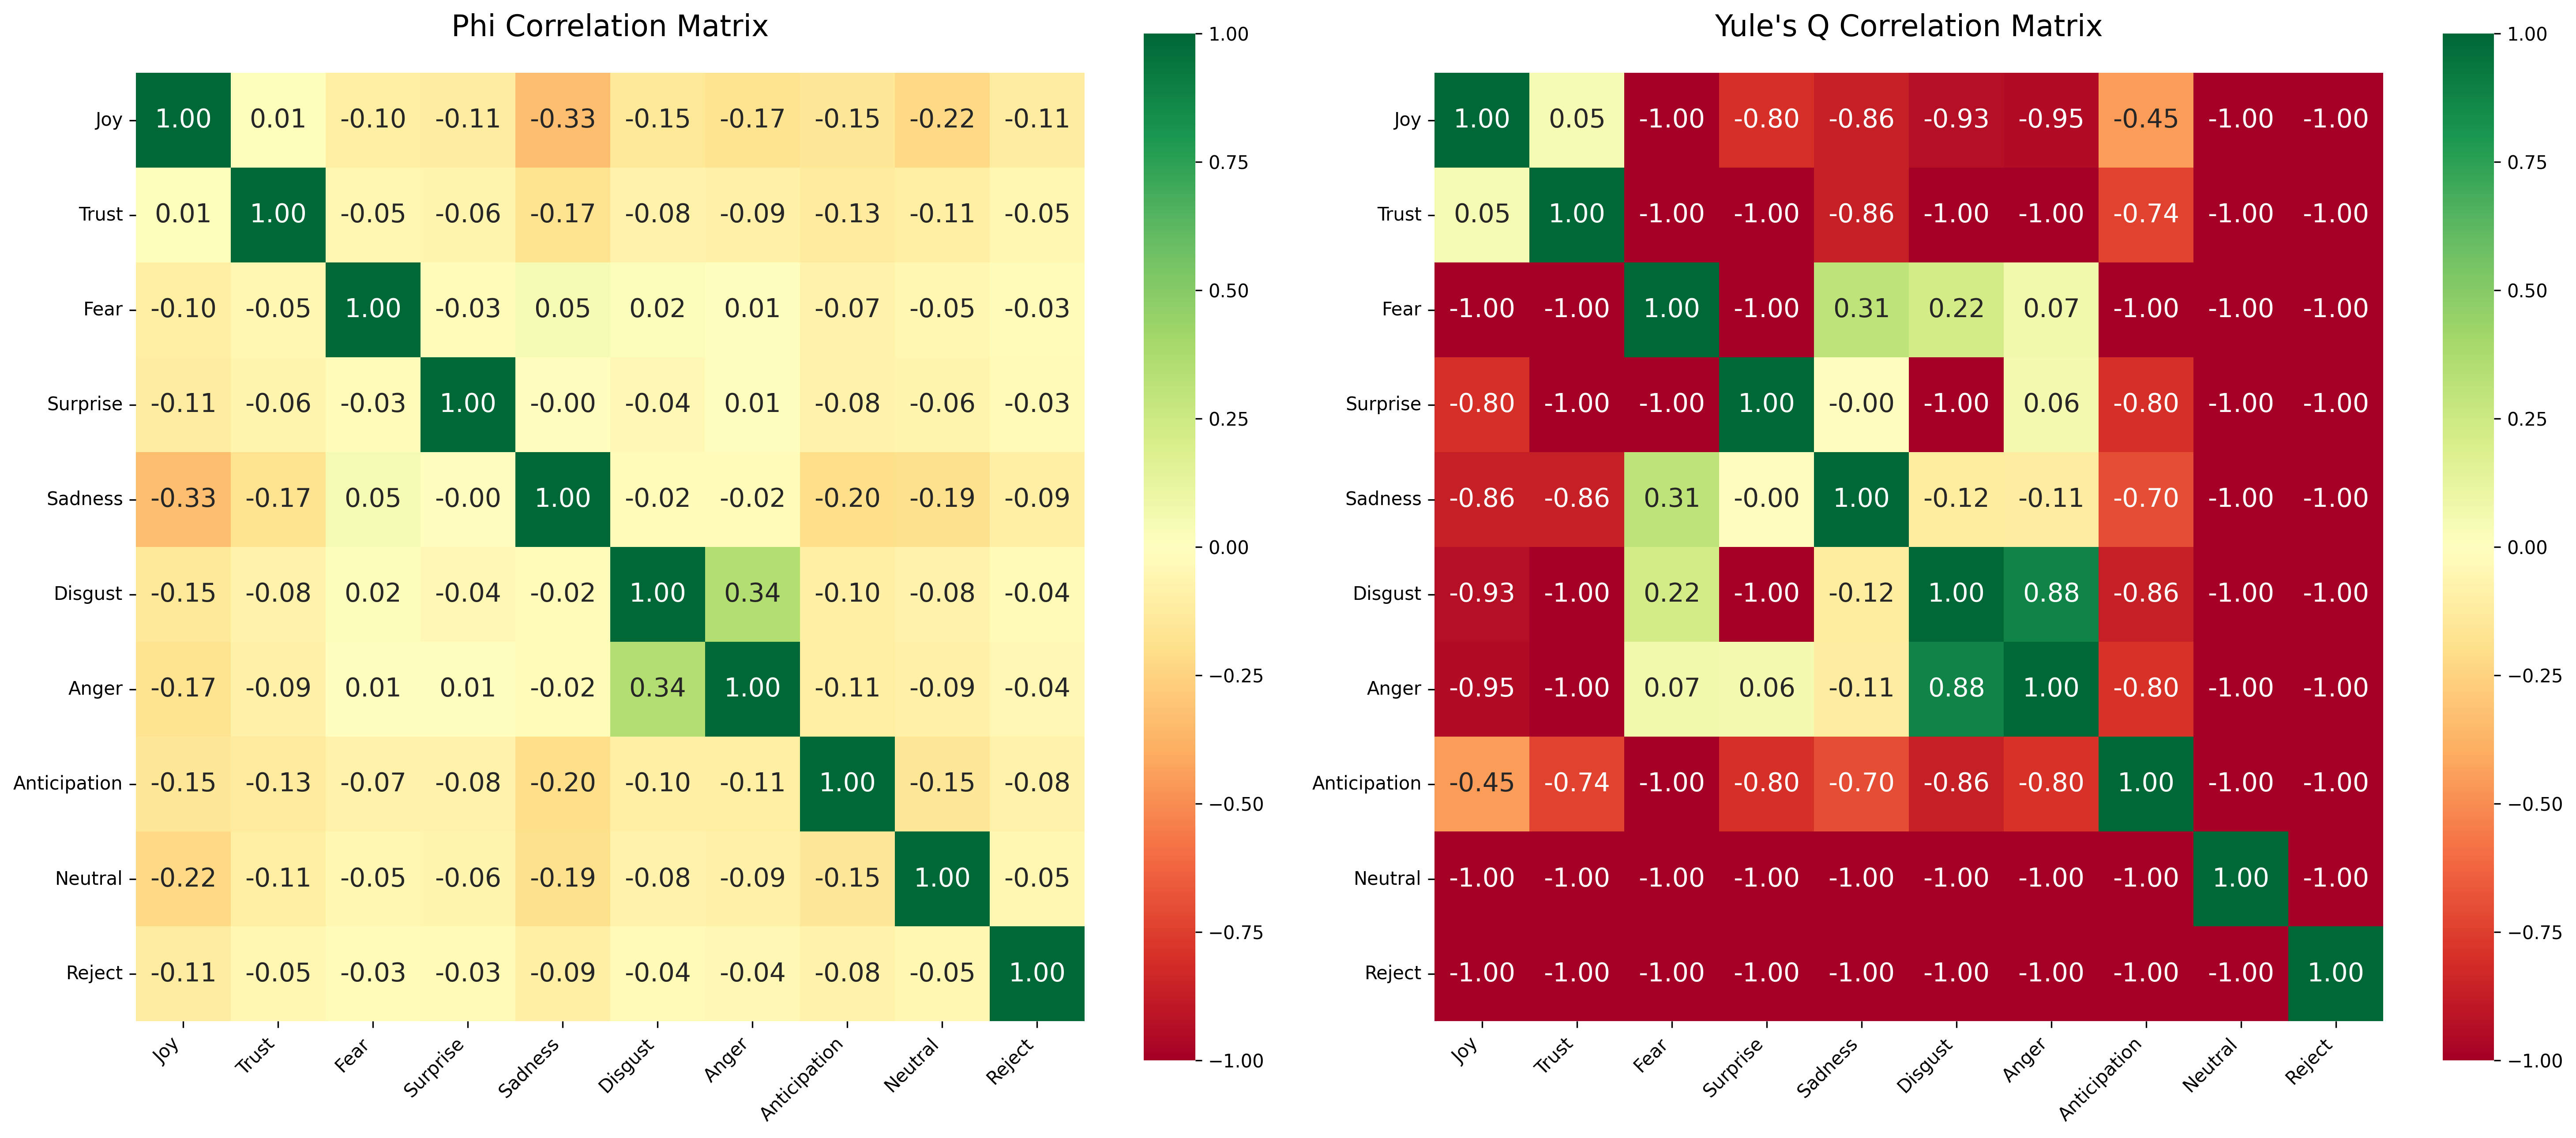

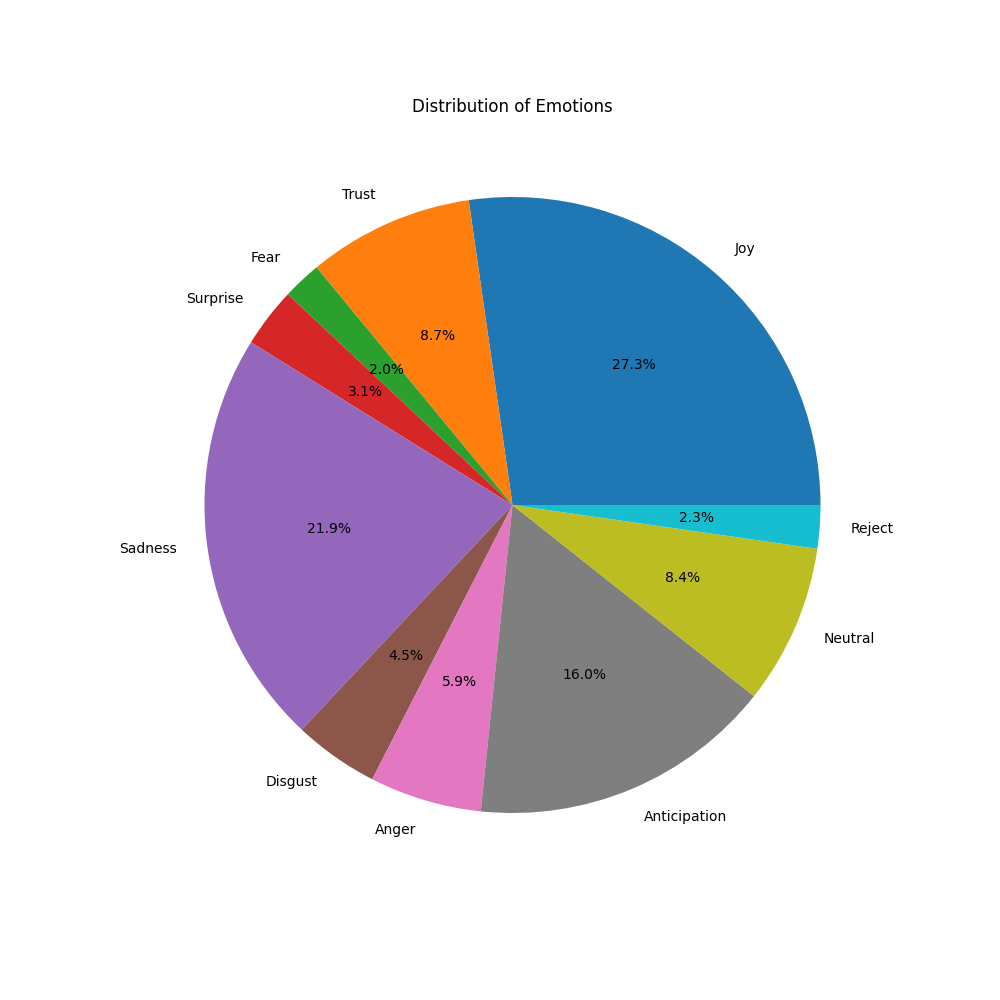

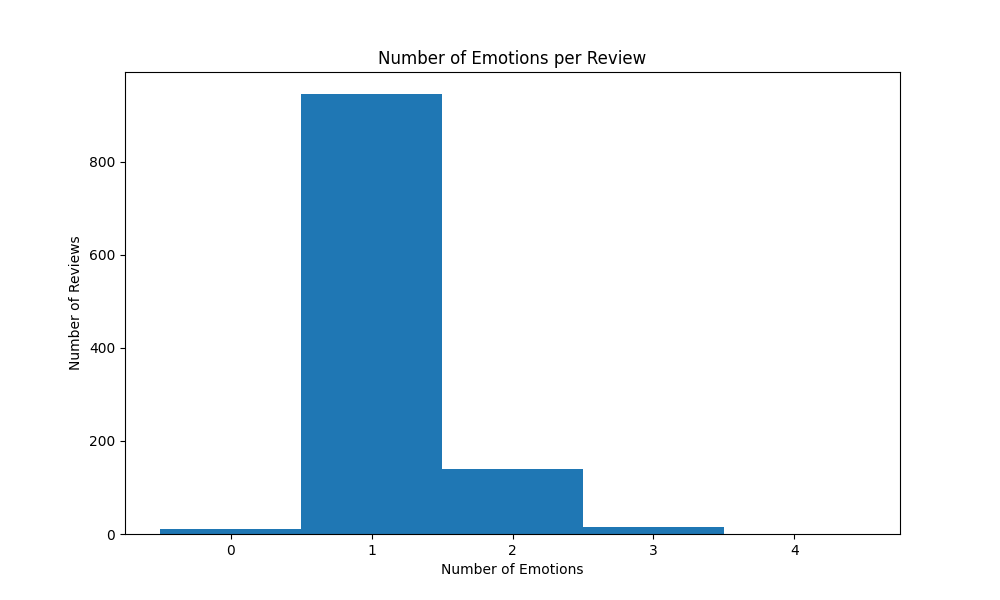

Emotion Distribution:
              Count  Percentage
Joy             348       27.27
Sadness         279       21.87
Anticipation    204       15.99
Trust           111        8.70
Neutral         107        8.39
Anger            75        5.88
Disgust          57        4.47
Surprise         40        3.13
Reject           29        2.27
Fear             26        2.04

Emotions per Review Statistics:
count    1112.000000
mean        1.147482
std         0.421959
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         4.000000

Histogram Data (Emotions per Review):
Number of Emotions | Count of Reviews
-----------------------------------
        0         |       10       
        1         |       946      
        2         |       139      
        3         |       16       
        4         |        1       


Reviews with Zero Emotions:
------------------------
819c67a1-b726-4b72-8fc6-38618236c4c6
e7a301c6-f92a-4f05-b022-1d378813c1ba
929

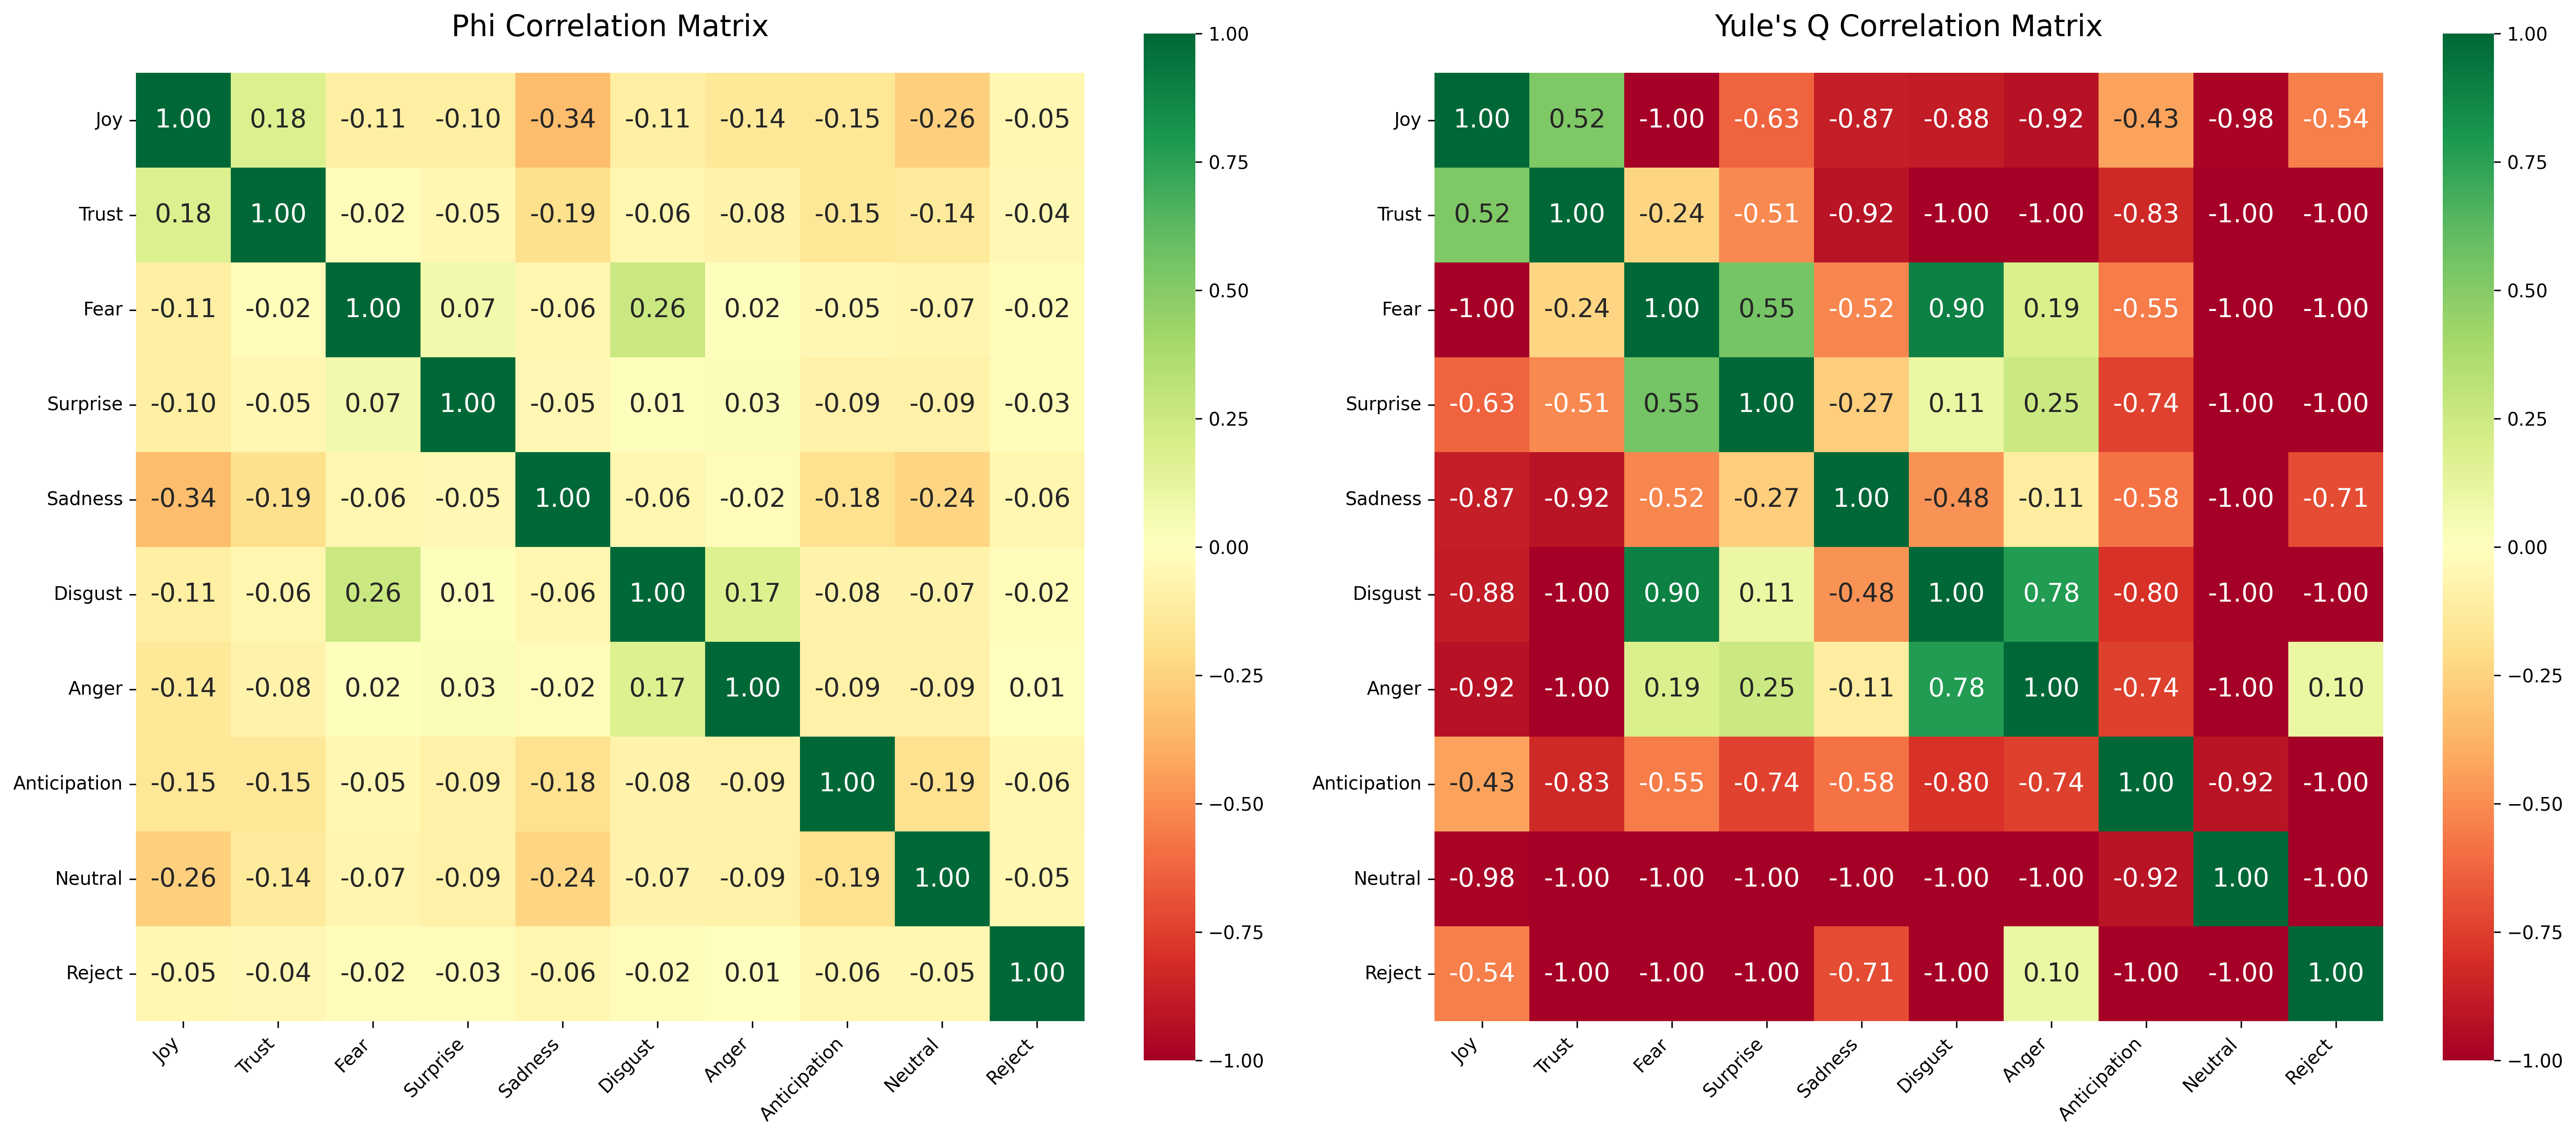

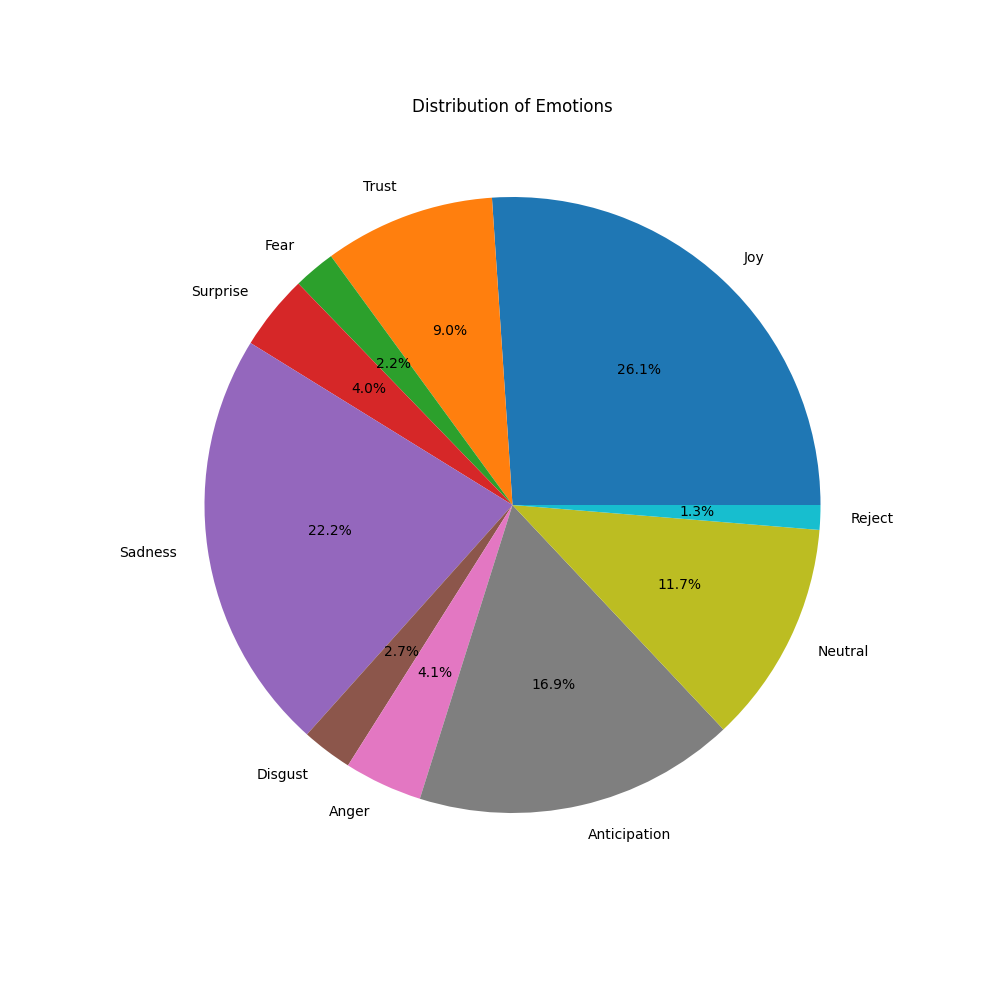

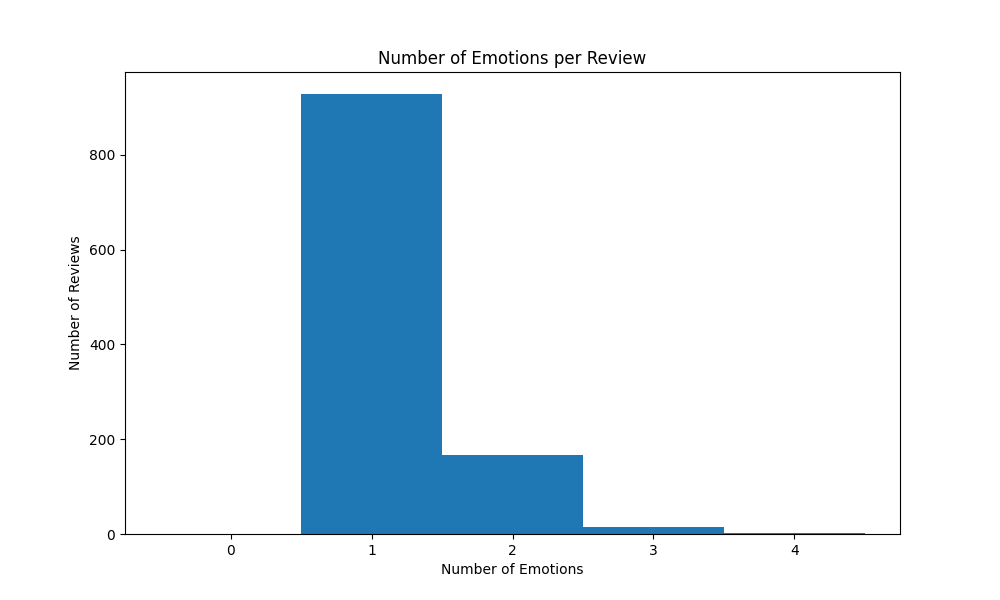

Emotion Distribution:
              Count  Percentage
Joy             343       26.06
Sadness         292       22.19
Anticipation    222       16.87
Neutral         154       11.70
Trust           118        8.97
Anger            54        4.10
Surprise         52        3.95
Disgust          35        2.66
Fear             29        2.20
Reject           17        1.29

Emotions per Review Statistics:
count    1112.000000
mean        1.183453
std         0.437421
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         4.000000

Histogram Data (Emotions per Review):
Number of Emotions | Count of Reviews
-----------------------------------
        0         |        0       
        1         |       928      
        2         |       167      
        3         |       14       
        4         |        3       


Reviews with Zero Emotions:
------------------------


Phi Correlation Matrix:
                   Joy     Trust      Fear  Surpris

In [25]:
for name, agreement_file in agreements.items():  # per-LLM files from the previous step
    !{py} {codePath}code/evaluation/emotion_statistics.py --input-file {agreement_file} --output-dir {dataPath}/evaluation/statistics/{name}
    show(f"{dataPath}/evaluation/statistics/{name}")

We measure the average pairwise Cohen's Kappa agreement (averaged across iterations) between the individual human annotators (Ann_1 to Ann_5), the consolidated human annotators (Ann_A), each LLM's consolidated annotations (GPT_A, Mistral_A, Gemini_A) and the fully consolidated LLM annotations (LLM_A). The result is shown as a heatmap below.

Saved heatmap to: ./SourceCode/ReplicationPackage/data/COPY//evaluation/kappa/agreement-statistics-ALL_heatmap.png
Agreement statistics have been saved to: ./SourceCode/ReplicationPackage/data/COPY//evaluation/kappa/agreement-statistics-ALL.xlsx


2026-11-09 13:41:11,106 - INFO - Excluding iterations: [0, 1, 2]
2026-11-09 13:41:11,107 - INFO - Created output folder: ./SourceCode/ReplicationPackage/data/COPY//evaluation/kappa/
2026-11-09 13:41:11,107 - INFO - Starting to process iterations
2026-11-09 13:41:11,107 - INFO - Starting to process folder: ./SourceCode/ReplicationPackage/data/COPY//annotations/iterations/
2026-11-09 13:41:11,108 - INFO - Skipping excluded iteration: 0
2026-11-09 13:41:11,108 - INFO - Skipping excluded iteration: 1
2026-11-09 13:41:11,108 - INFO - Processing iteration folder: iteration_10
2026-11-09 13:41:11,108 - INFO - Processing annotation file: iteration_10_agreement.xlsx
2026-11-09 13:41:11,108 - INFO - Processing annotation file: iteration_10_agreement_Ann_1-Ann_2-Ann_3-Ann_4-Ann_5.xlsx
2026-11-09 13:41:11,134 - INFO - Starting to parse annotations
2026-11-09 13:41:11,138 - INFO - Successfully parsed 100 annotations
2026-11-09 13:41:11,138 - INFO - Processing annotation file: iteration_10_agreement

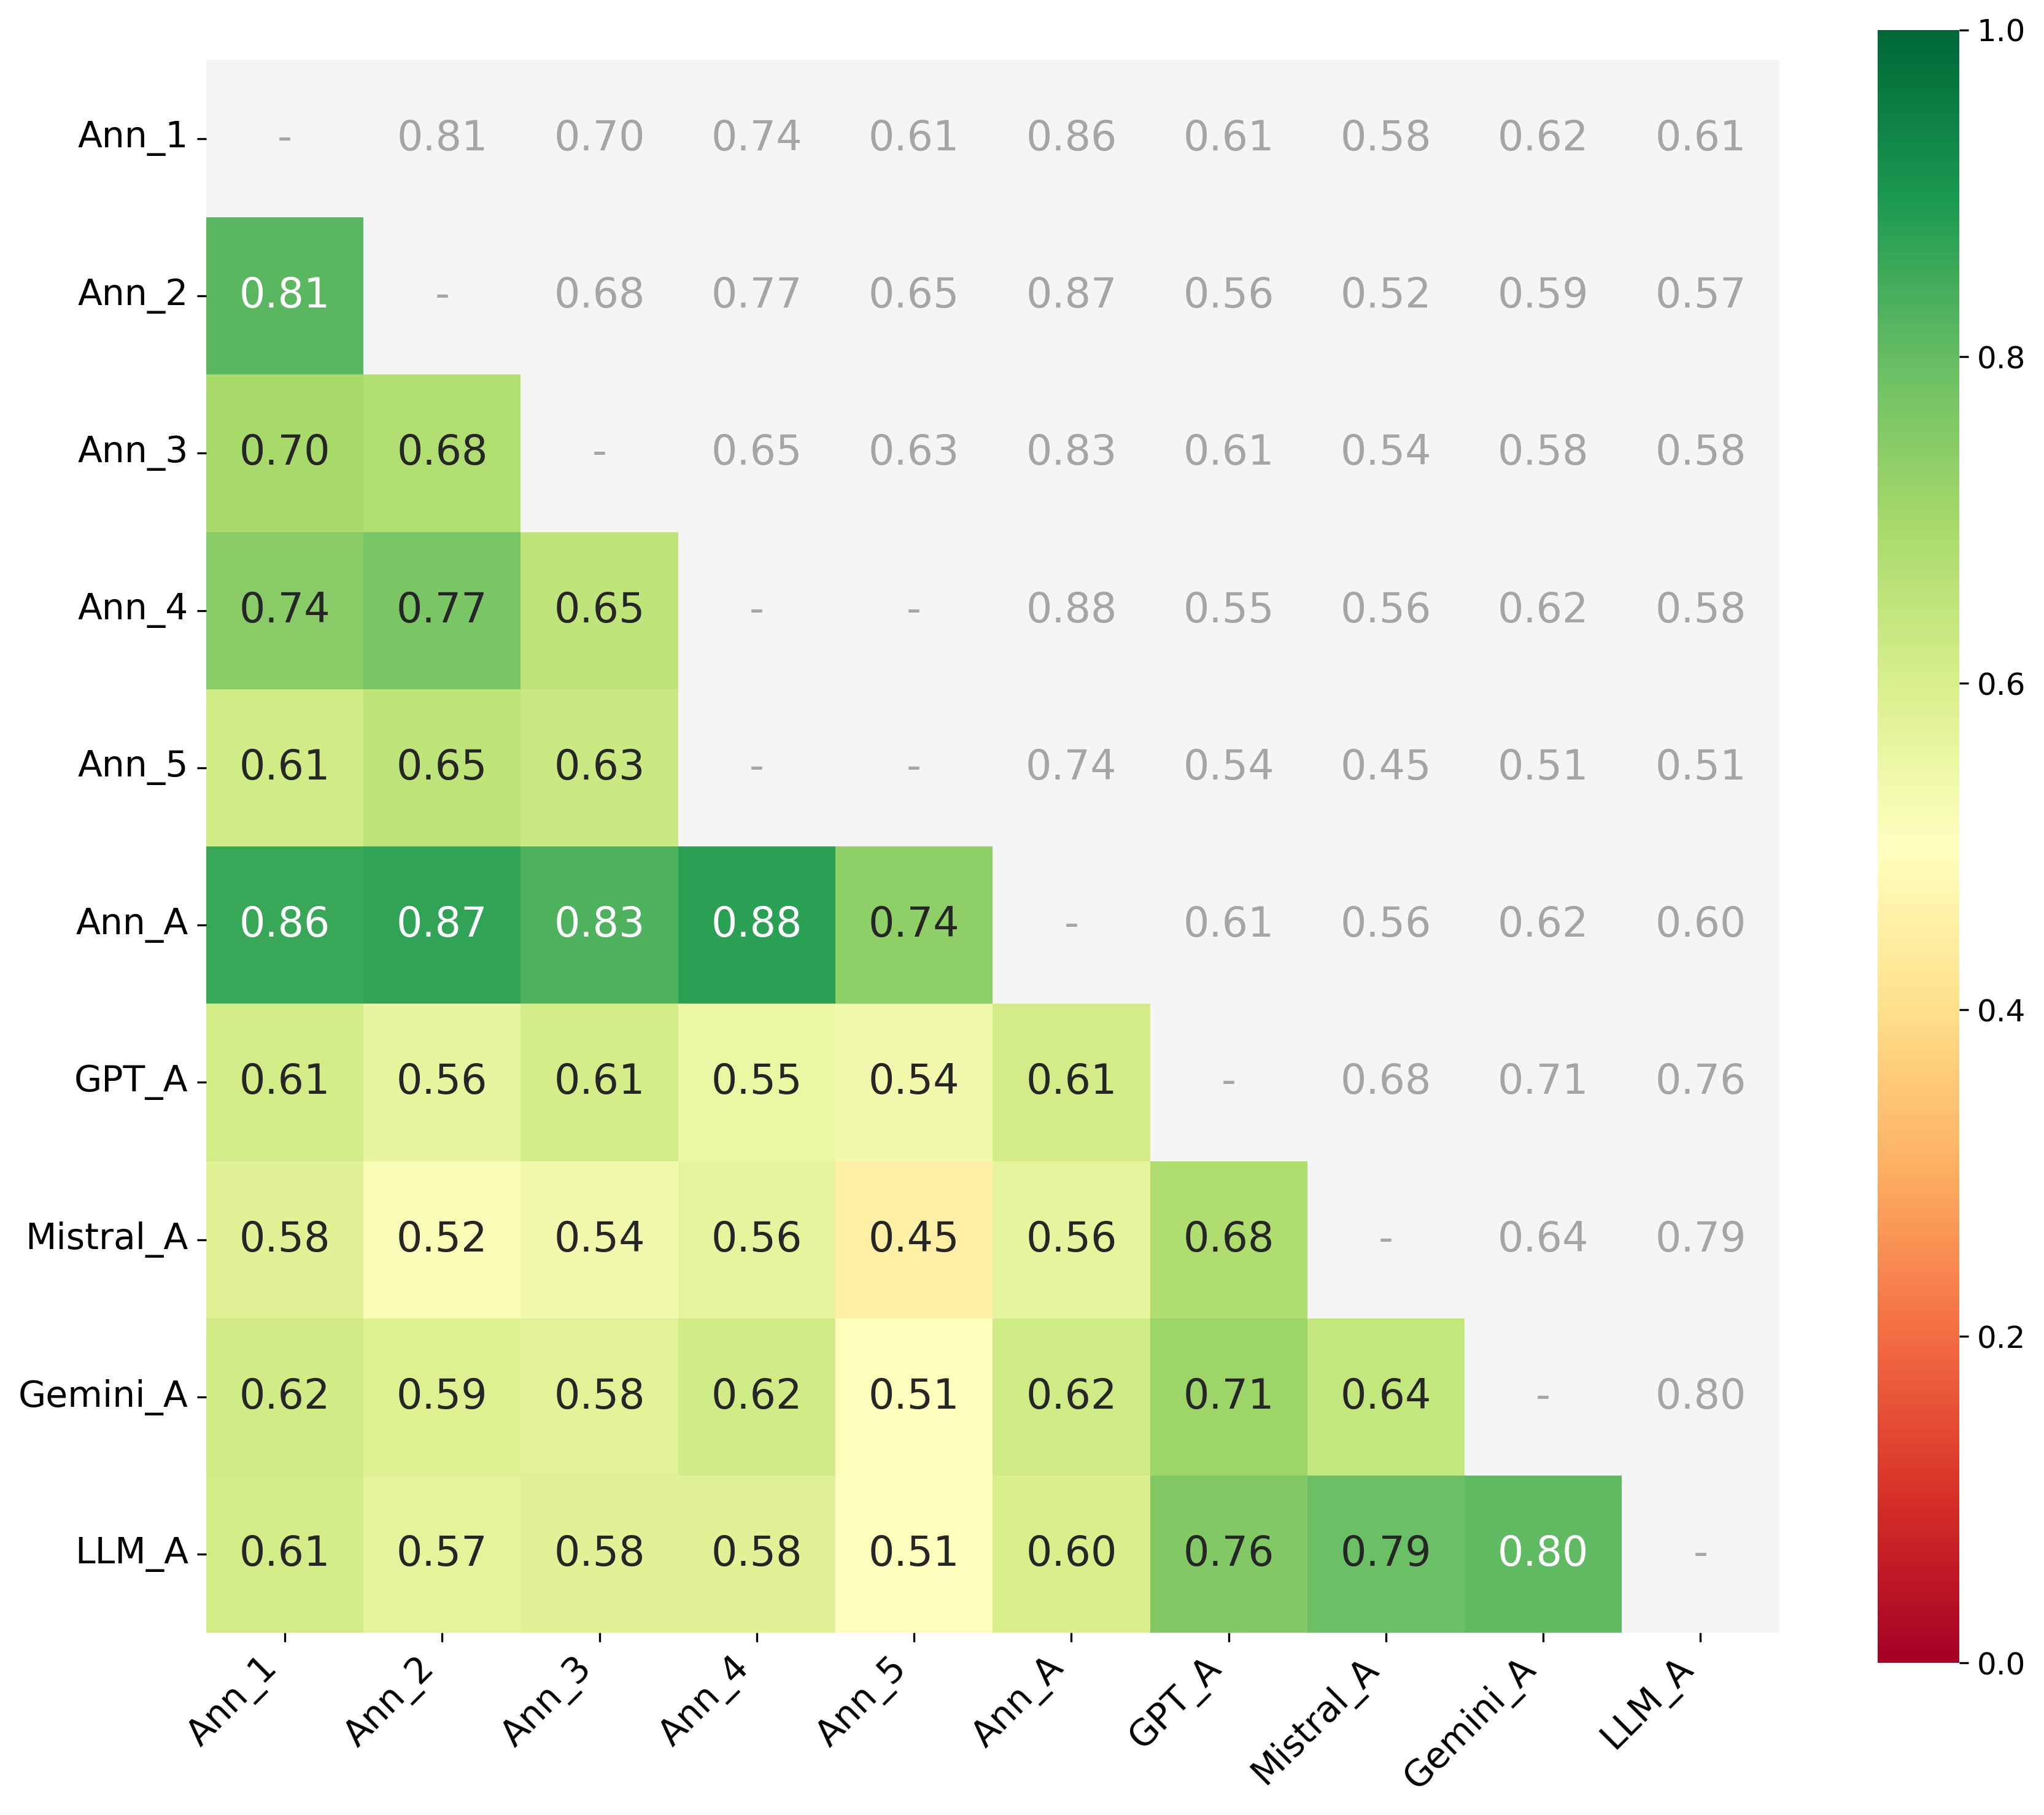

In [26]:
exclude = "0,1,2"  # Edit: iterations to leave out. The annotators and heatmap labels are set at the top of kappa.py
!{py} {codePath}code/evaluation/kappa.py --input_folder {dataPath}/annotations/iterations/ --output_folder {dataPath}/evaluation/kappa/ --exclude {exclude}
show(f"{dataPath}/evaluation/kappa")

Lastly, we measure the correctness (accuracy, precision, recall, and F1 score) of a set of annotated reviews (here, each LLM's consolidated annotations) against a given ground truth.

gpt-4o


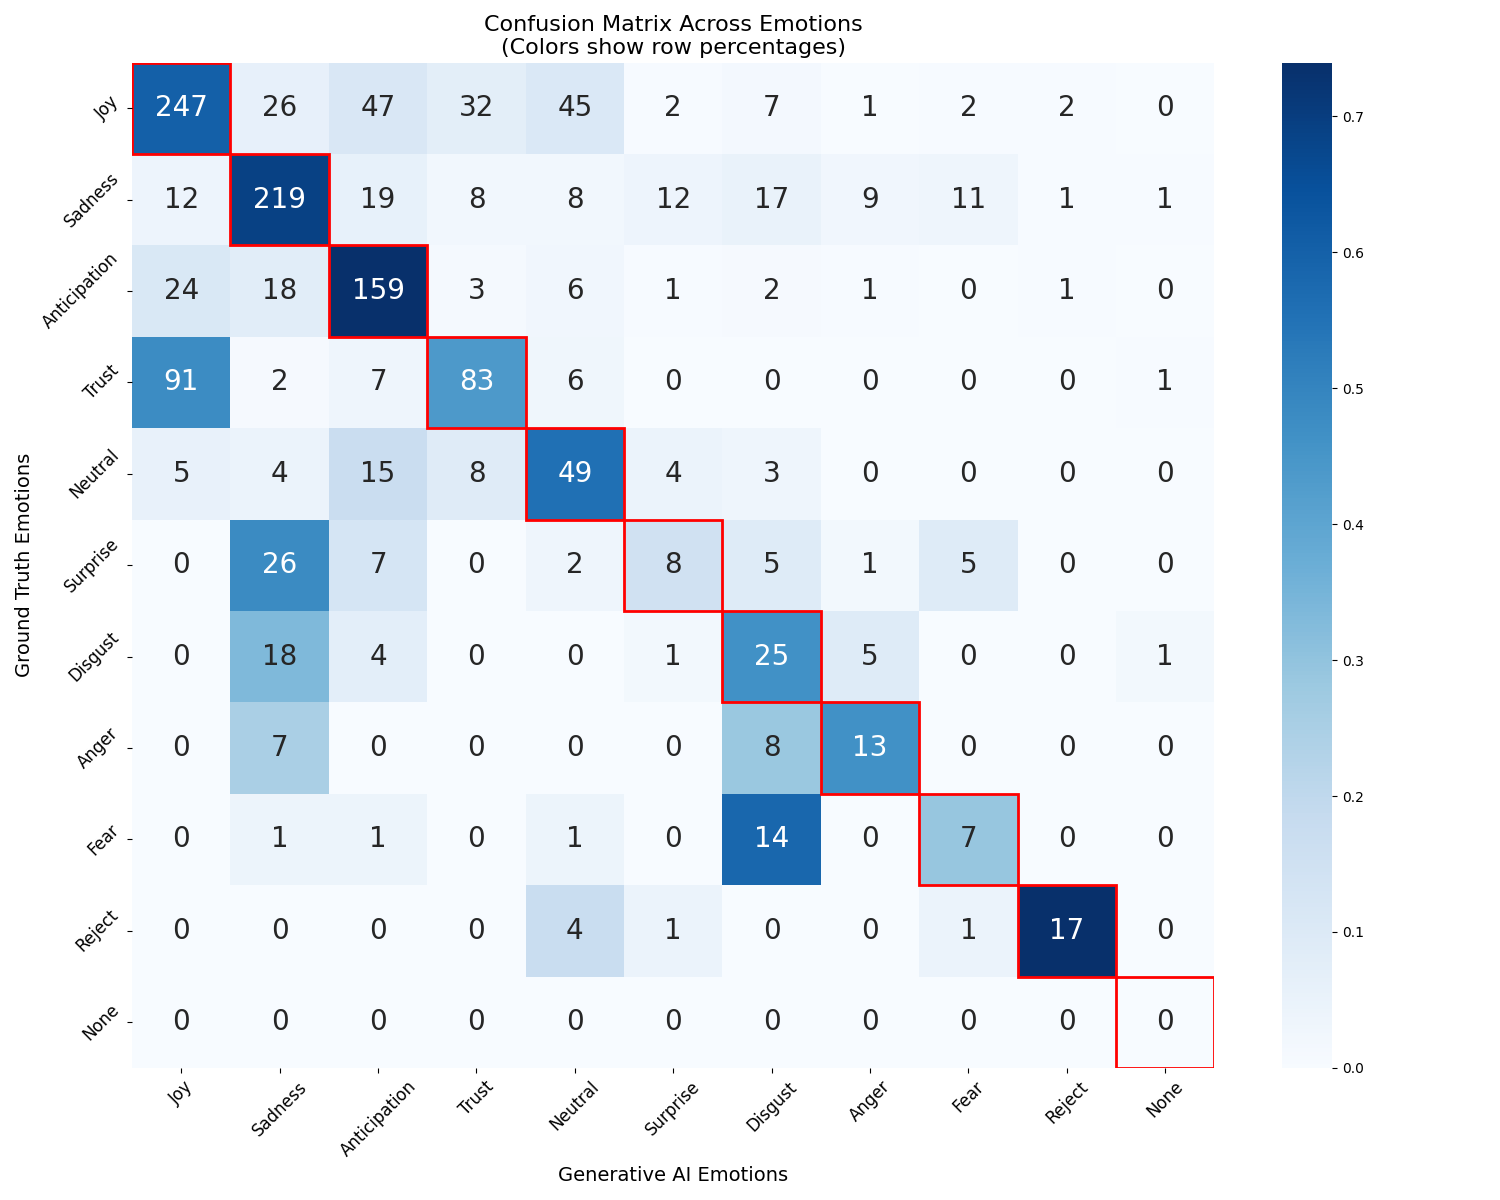

,Emotion,Accuracy,Precision,Recall,F1
0,Joy,0.806655,0.732938,0.663978,0.696756
1,Sadness,0.881295,0.820225,0.722772,0.768421
2,Anticipation,0.940647,0.787129,0.873626,0.828125
3,Trust,0.902878,0.680328,0.546053,0.605839
4,Neutral,0.909173,0.441441,0.556818,0.492462
5,Surprise,0.944245,0.333333,0.148148,0.205128
6,Disgust,0.937050,0.357143,0.500000,0.416667
7,Anger,0.976619,0.520000,0.481481,0.500000
8,Fear,0.972122,0.333333,0.291667,0.311111
9,Reject,0.993705,0.894737,0.772727,0.829268


mistral-large-2411


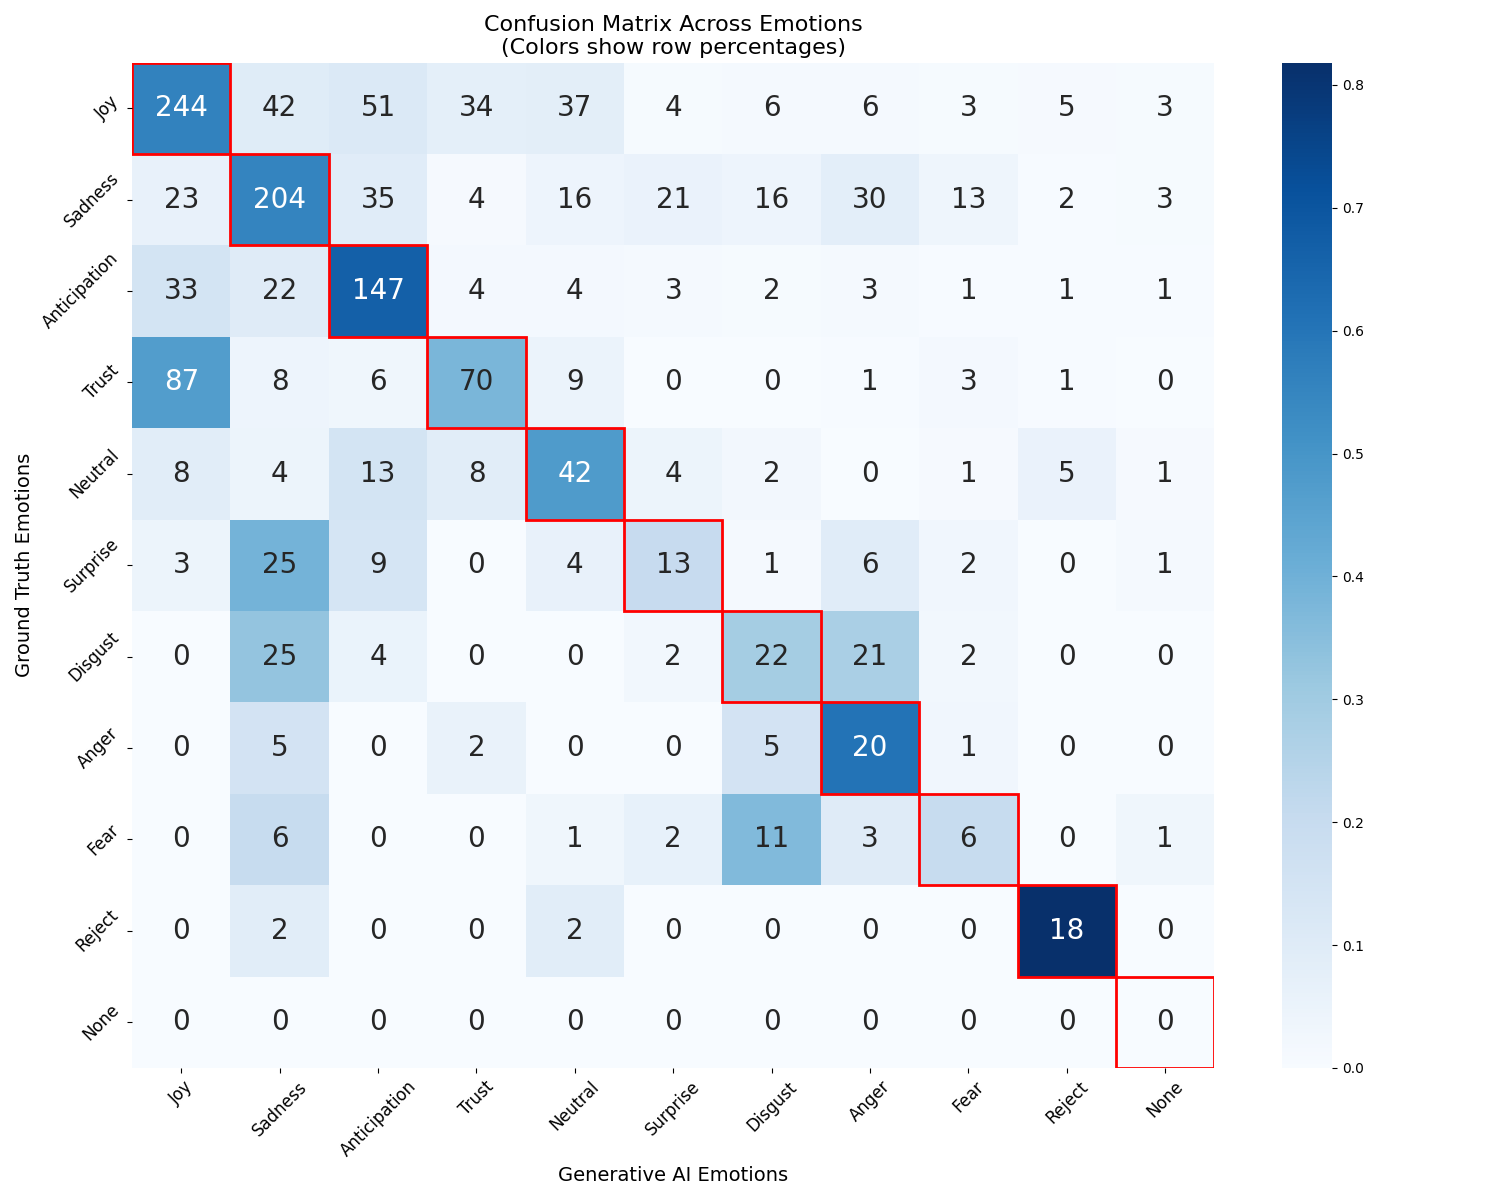

,Emotion,Accuracy,Precision,Recall,F1
0,Joy,0.791367,0.701149,0.655914,0.677778
1,Sadness,0.843525,0.731183,0.673267,0.701031
2,Anticipation,0.917266,0.720588,0.807692,0.761658
3,Trust,0.889388,0.630631,0.460526,0.532319
4,Neutral,0.900180,0.392523,0.477273,0.430769
5,Surprise,0.938849,0.325000,0.240741,0.276596
6,Disgust,0.943345,0.385965,0.440000,0.411215
7,Anger,0.944245,0.266667,0.740741,0.392157
8,Fear,0.965827,0.230769,0.250000,0.240000
9,Reject,0.986511,0.620690,0.818182,0.705882


gemini-2-0-flash


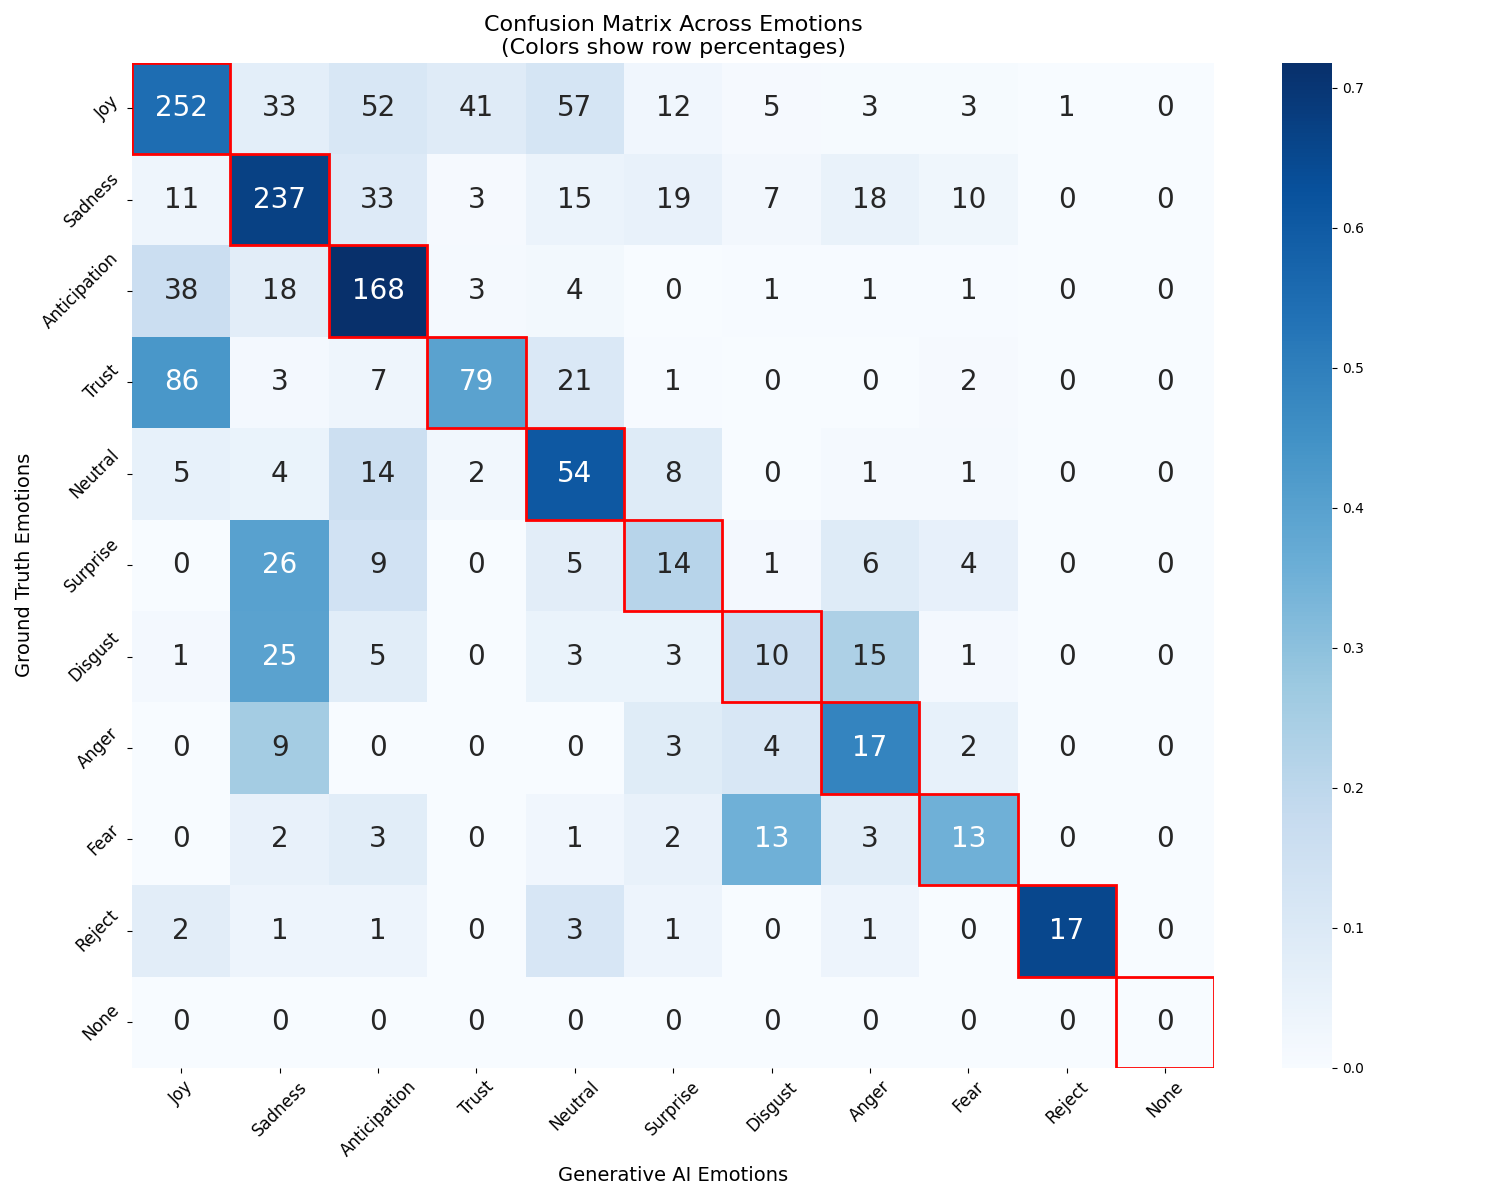

,Emotion,Accuracy,Precision,Recall,F1
0,Joy,0.810252,0.734694,0.677419,0.704895
1,Sadness,0.891187,0.811644,0.782178,0.796639
2,Anticipation,0.938849,0.756757,0.923077,0.831683
3,Trust,0.899281,0.669492,0.519737,0.585185
4,Neutral,0.879496,0.350649,0.613636,0.446281
5,Surprise,0.929856,0.269231,0.259259,0.264151
6,Disgust,0.941547,0.285714,0.200000,0.235294
7,Anger,0.957734,0.314815,0.629630,0.419753
8,Fear,0.975719,0.448276,0.541667,0.490566
9,Reject,0.995504,1.000000,0.772727,0.871795


In [27]:
for name, agreement_file in agreements.items():
    !{py} {codePath}code/evaluation/correctness.py --ground_truth {ground_truth} --predictions {agreement_file} --output_dir {dataPath}/evaluation/correctness/{name}
    print(name)
    show(f"{dataPath}/evaluation/correctness/{name}")